In [1]:
import os
import uuid
import hashlib
import platform
import numpy as np
import scipy
import matplotlib
import pandas as pd

# 修改为自己的学号
STUDENT_ID = 20244080230
CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV", "base")
print(f"[Conda 环境] {CONDA_ENV}")
MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")
print(f"[版本] numpy {np.__version__} | scipy {scipy.__version__} | "
      f"matplotlib {matplotlib.__version__} | pandas {pd.__version__}")

[Conda 环境] exp01
[学号] 20244080230
[机器指纹] 2d80c6ac8fb85281
[RUN_ID] 20244080230-2d80c6ac8fb85281
[版本] numpy 2.5.4 | scipy 1.18.1 | matplotlib 3.11.2 | pandas 3.0.6


## 实验1：NumPy 数组、数据类型与索引

**思路**

- 三种 ndarray 分别用整型、浮点、布尔字面量构造，`dtype` / `shape` / `ndim` 一次性打印出来。
- `reshape` 只改变"视图的形状"，元素总个数必须和原数组一致。
- 索引分三类：按行取（`a[1]`）、按列切片（`a[:, 0:3]`）、布尔掩码取元素（`a[a > 6]`）。
- 多条件掩码必须加括号：`(a < 2) | (a > 7)`，否则 `|` 的优先级会出错。
- `*` / `np.multiply` 是逐元素乘；`@` / `np.matmul` 才是矩阵乘法。

In [2]:
# bonjour
a_int = np.array([1, 2, 3, 4])
a_float = np.array([1.5, 2.5, 3.5])
a_bool = np.array([True, False, True, False])

for name, arr in [("整数", a_int), ("浮点", a_float), ("布尔", a_bool)]:
    print(f"{name}: {arr!s:<24} dtype={arr.dtype}  shape={arr.shape}  ndim={arr.ndim}")

整数: [1 2 3 4]                dtype=int64  shape=(4,)  ndim=1
浮点: [1.5 2.5 3.5]            dtype=float64  shape=(3,)  ndim=1
布尔: [ True False  True False] dtype=bool  shape=(4,)  ndim=1


**NumPy 数组与 Python 列表的差别**：Python 列表可以混装任意对象（`[1, "a", 3.0]`），
每个元素是独立的 Python 对象；而 ndarray 是**同构**的——所有元素共用同一个 `dtype`，
数据存在连续的定长内存块里。因此数组占用更少、运算更快（可以向量化、由 C 循环执行），
但插入不同 dtype 的元素时会被"向上提升"（例如整型数组里塞浮点会变成 float64）。

In [3]:
arr = np.arange(12)
print("一维:", arr, "| shape:", arr.shape)

a34 = arr.reshape(3, 4)
a232 = arr.reshape(2, 3, 2)
print("reshape(3, 4):\n", a34)
print("reshape(2, 3, 2):\n", a232)
print("元素总数: 3*4 =", 3 * 4, "；2*3*2 =", 2 * 3 * 2, "；原数组长度 =", arr.size)

一维: [ 0  1  2  3  4  5  6  7  8  9 10 11] | shape: (12,)
reshape(3, 4):
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
reshape(2, 3, 2):
 [[[ 0  1]
  [ 2  3]
  [ 4  5]]

 [[ 6  7]
  [ 8  9]
  [10 11]]]
元素总数: 3*4 = 12 ；2*3*2 = 12 ；原数组长度 = 12


改变形状的条件：**新形状各维度的乘积必须等于原数组的元素总数**（这里是 12），
否则会抛 `ValueError: cannot reshape array of size 12 into shape (...)`。

In [4]:
print("取第 2 行 a34[1]      :", a34[1], "| shape:", a34[1].shape)
print("取第 1~3 列 a34[:, 0:3]:\n", a34[:, 0:3], "\n| shape:", a34[:, 0:3].shape)
print("取大于 6 的元素        :", a34[a34 > 6], "| shape:", a34[a34 > 6].shape)

取第 2 行 a34[1]      : [4 5 6 7] | shape: (4,)
取第 1~3 列 a34[:, 0:3]:
 [[ 0  1  2]
 [ 4  5  6]
 [ 8  9 10]] 
| shape: (3, 3)
取大于 6 的元素        : [ 7  8  9 10 11] | shape: (5,)


In [5]:
arr10 = np.arange(10)
print("arr10 =", arr10)

mask_or = (arr10 < 2) | (arr10 > 7)
mask_and = (arr10 > 3) & (arr10 < 7)
print("小于 2 或大于 7（|）  :", arr10[mask_or])
print("大于 3 且小于 7（&）  :", arr10[mask_and])
print("logical_or 结果       :", arr10[np.logical_or(arr10 < 2, arr10 > 7)])
print("logical_and 结果      :", arr10[np.logical_and(arr10 > 3, arr10 < 7)])

arr10 = [0 1 2 3 4 5 6 7 8 9]
小于 2 或大于 7（|）  : [0 1 8 9]
大于 3 且小于 7（&）  : [4 5 6]
logical_or 结果       : [0 1 8 9]
logical_and 结果      : [4 5 6]


In [6]:
A = np.array([[1, 2], [3, 4]])
B = np.array([[5, 6], [7, 8]])

print("A * B（逐元素）:\n", A * B)
print("np.multiply(A, B):\n", np.multiply(A, B))
print("A @ B（矩阵乘）:\n", A @ B)
print("np.matmul(A, B):\n", np.matmul(A, B))

A * B（逐元素）:
 [[ 5 12]
 [21 32]]
np.multiply(A, B):
 [[ 5 12]
 [21 32]]
A @ B（矩阵乘）:
 [[19 22]
 [43 50]]
np.matmul(A, B):
 [[19 22]
 [43 50]]


**逐元素乘法 vs 矩阵乘法**：`A * B`（等价于 `np.multiply`）是把对应位置的元素相乘，
结果形状不变；`A @ B`（等价于 `np.matmul`）是线性代数乘法——第 i 行与第 j 列做内积，
要求 A 的列数等于 B 的行数。上面两种矩阵乘结果相同，因为 `A * B` 恰好也满足条件，
但数值完全不同（例如左上角：逐元素 1×5=5，矩阵乘 1×5+2×7=19）。

## 实验2：随机抽样、统计与缺失值

**思路**

- 用 `np.random.default_rng(seed)` 固定种子（可复现），`normal()` 生成 1000 个 N(70, 10²) 成绩，
  再用 `np.clip` 截到 0~100。
- 不放回抽样用 `choice(..., replace=False)`；加权抽样再传 `p=`（权重之和为 1）。
- `permutation` 返回打乱后的**新数组**，`shuffle` 在**原数组上**打乱。
- 缺失值用 `np.nan` 表示，普通 `mean/sum/std` 遇到 nan 会直接变 nan，要用 `nanmean` 等。
- 最后把带缺失的成绩整理成内存里的 DataFrame，供后续实验使用（不写磁盘）。

In [7]:
rng = np.random.default_rng(42)                 # 固定随机种子
scores = np.clip(rng.normal(loc=70, scale=10, size=1000), 0, 100)

print("样本数:", scores.size)
print(f"最小值: {scores.min():.2f}")
print(f"最大值: {scores.max():.2f}")
print(f"均值  : {scores.mean():.2f}")
print(f"标准差: {scores.std():.2f}")
print(f"极差  : {scores.max() - scores.min():.2f}")

样本数: 1000
最小值: 33.52
最大值: 100.00
均值  : 69.71
标准差: 9.88
极差  : 66.48


In [8]:
pool = np.arange(1, 11)
rng_choice = np.random.default_rng(7)

uniform = rng_choice.choice(pool, size=5, replace=False)
weights = pool / pool.sum()                     # 权重与数值成正比
weighted = rng_choice.choice(pool, size=5, replace=False, p=weights)

print("候选:", pool)
print("均匀抽样（不放回）      :", uniform)
print("按数值加权（不放回）    :", weighted)
print("权重之和:", round(weights.sum(), 6))

候选: [ 1  2  3  4  5  6  7  8  9 10]
均匀抽样（不放回）      : [ 5  8  6 10  9]
按数值加权（不放回）    : [10  1  9  7  4]
权重之和: 1.0


In [9]:
base = np.arange(10)
rng_perm = np.random.default_rng(11)

perm = rng_perm.permutation(base)               # 返回新数组，原数组不变
print("原数组 base            :", base)
print("permutation 得到的新数组:", perm)
print("base 仍然是             :", base)

shuffled = base.copy()
rng_perm.shuffle(shuffled)                      # 原地打乱
print("shuffle 后的 shuffled   :", shuffled)
print("base 仍然是             :", base)

原数组 base            : [0 1 2 3 4 5 6 7 8 9]
permutation 得到的新数组: [8 5 6 1 9 3 4 2 7 0]
base 仍然是             : [0 1 2 3 4 5 6 7 8 9]
shuffle 后的 shuffled   : [3 2 0 9 8 1 4 6 7 5]
base 仍然是             : [0 1 2 3 4 5 6 7 8 9]


In [10]:
scores_nan = scores.astype(float).copy()
scores_nan[[9, 19, 29]] = np.nan                # 第 10、20、30 个（1-based）

print("普通均值 mean()      :", scores_nan.mean())
print("忽略缺失 nanmean()   :", np.nanmean(scores_nan))
print("缺失值个数           :", int(np.isnan(scores_nan).sum()))
print("普通 sum()           :", scores_nan.sum())
print("普通 std()           :", scores_nan.std())

普通均值 mean()      : nan
忽略缺失 nanmean()   : 69.71315691233939
缺失值个数           : 3
普通 sum()           : nan
普通 std()           : nan


**nan 对统计函数的影响**：`nan` 参与任何算术运算都会"传染"成 `nan`，所以
`mean()` / `sum()` / `std()` 直接返回 `nan`（不是报错，但结果没用）。
要用 `np.nanmean` / `np.nansum` / `np.nanstd` 这类忽略缺失的版本，
或者先 `scores[~np.isnan(scores)]` 过滤掉。

In [11]:
df_scores = pd.DataFrame({                      # 只在内存里，不写磁盘
    "index": np.arange(1, len(scores_nan) + 1),
    "score": scores_nan,
})
print("表格形状:", df_scores.shape)
print(df_scores.head())
print("表中缺失值个数:", int(df_scores["score"].isna().sum()))

表格形状: (1000, 2)
   index      score
0      1  73.047171
1      2  59.600159
2      3  77.504512
3      4  79.405647
4      5  50.489648
表中缺失值个数: 3


## 实验3：SciPy 数值计算与 Matplotlib 可视化

**思路**

- 线性方程组写成 `A @ [x, y] = b`，用 `scipy.linalg.solve` 解，再代回 `A @ sol` 验证。
- 求根用 `optimize.root`，给不同初值（正/负）就能收敛到不同的根。
- 求极小用 `optimize.minimize`，再和解析解（对 x²+x+2 求导得 x = -0.5、f = 1.75）对照。
- 两组独立样本用 `scipy.stats.ttest_ind`，先固定种子，再按 0.05 水平判断。
- 作图统一给出标题、坐标轴标签，折线图加图例；图直接在 notebook 里显示，不落盘。

In [12]:
A = np.array([[3.0, 1.0], [1.0, 2.0]])
b = np.array([9.0, 8.0])

sol = scipy.linalg.solve(A, b)
print("解向量:", sol)
print(f"x = {sol[0]:.6f}, y = {sol[1]:.6f}")
print("代回 A @ sol =", A @ sol, " 与 b 相等:", np.allclose(A @ sol, b))

解向量: [2. 3.]
x = 2.000000, y = 3.000000
代回 A @ sol = [9. 8.]  与 b 相等: True


In [13]:
def f(x):
    return x**2 - 2

for guess in [1.0, -1.0]:
    res = scipy.optimize.root(f, x0=guess)
    print(f"初值 {guess:>5}: success={res.success}  root={res.x[0]:.12f}  "
          f"f(root)={f(res.x[0]):.3e}")
print("解析正根 sqrt(2) =", np.sqrt(2))

初值   1.0: success=True  root=1.414213562373  f(root)=-8.882e-16
初值  -1.0: success=True  root=-1.414213562373  f(root)=-8.882e-16
解析正根 sqrt(2) = 1.4142135623730951


In [14]:
def g(x):
    return x**2 + x + 2

res = scipy.optimize.minimize(g, x0=0.0)
print("极小点 x* =", res.x[0])
print("函数值 f(x*) =", res.fun)
print("解析解: x* = -0.5, f = 1.75")
print("与解析解一致:", np.isclose(res.x[0], -0.5), np.isclose(res.fun, 1.75))

极小点 x* = -0.5000000064345924
函数值 f(x*) = 1.75
解析解: x* = -0.5, f = 1.75
与解析解一致: True True


In [15]:
rng_t = np.random.default_rng(2024)
sample1 = rng_t.normal(loc=0.0, scale=1.0, size=100)
sample2 = rng_t.normal(loc=1.0, scale=1.0, size=100)

t_stat, p_value = scipy.stats.ttest_ind(sample1, sample2)
print(f"样本1: 均值 {sample1.mean():.4f}, 标准差 {sample1.std(ddof=1):.4f}")
print(f"样本2: 均值 {sample2.mean():.4f}, 标准差 {sample2.std(ddof=1):.4f}")
print(f"t 统计量 = {t_stat:.4f}")
print(f"p 值     = {p_value:.4e}")
print("0.05 显著性水平下:", "拒绝原假设（两组均值有显著差异）" if p_value < 0.05
      else "不能拒绝原假设（无显著差异）")

样本1: 均值 0.0790, 标准差 0.8824
样本2: 均值 0.8563, 标准差 1.0823
t 统计量 = -5.5665
p 值     = 8.3781e-08
0.05 显著性水平下: 拒绝原假设（两组均值有显著差异）


**t 检验结论**：p 值远小于 0.05，所以在 0.05 显著性水平下拒绝"两组均值相同"的原假设——
两组样本来自均值不同的分布（0 与 1），检验结果与构造数据的方式一致。

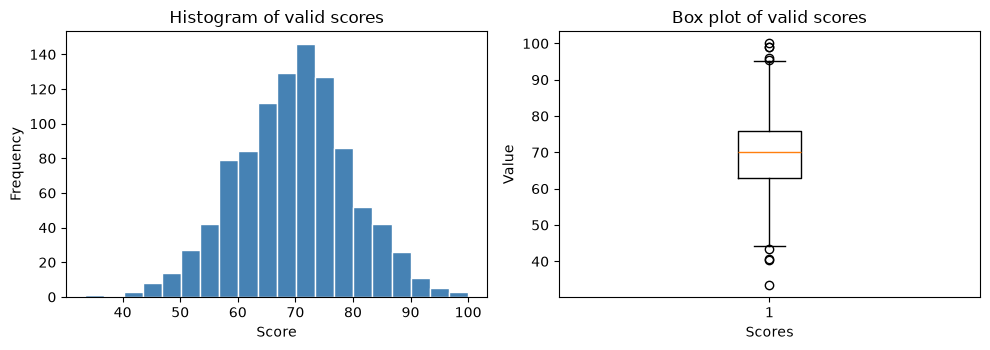

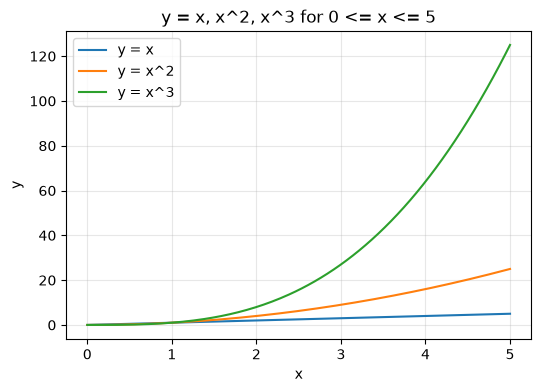

In [16]:
%matplotlib inline
import matplotlib.pyplot as plt

valid = scores_nan[~np.isnan(scores_nan)]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].hist(valid, bins=20, color="steelblue", edgecolor="white")
axes[0].set_title("Histogram of valid scores")
axes[0].set_xlabel("Score")
axes[0].set_ylabel("Frequency")

axes[1].boxplot(valid)
axes[1].set_title("Box plot of valid scores")
axes[1].set_xlabel("Scores")
axes[1].set_ylabel("Value")
plt.tight_layout()
plt.show()

x = np.linspace(0, 5, 200)
plt.figure(figsize=(6, 4))
plt.plot(x, x, label="y = x")
plt.plot(x, x**2, label="y = x^2")
plt.plot(x, x**3, label="y = x^3")
plt.title("y = x, x^2, x^3 for 0 <= x <= 5")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 实验4：pandas Series/DataFrame 与内存中的 CSV 读写

**思路**

- 用字典构造 DataFrame 并把 `Name` 设为行索引，三科总分/平均分分别用 `sum(axis=1)` / `mean(axis=1)`。
- `loc` 按**标签**取（`df.loc["Carol"]`），`iloc` 按**位置**取（`df.iloc[2]`）。
- `mean(axis=0)` 是列方向（每科），`mean(axis=1)` 是行方向（每人）。
- `apply` 逐行/逐列自定义计算，`agg` 一次要多个统计量，`rank` 给成绩排名。
- 分组统计用 `groupby`，`transform("mean")` 把组均值"广播"回每一行。
- `filter` 按"组"筛行；协方差/相关系数用 `.cov()` / `.corr()`。

In [17]:
records = {
    "Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
    "Group": ["A", "A", "B", "B", "A", "B"],
    "Math": [88, 72, 91, 65, 79, 84],
    "English": [90, 68, 85, 73, 92, 77],
    "Python": [95, 80, 89, 70, 86, 82],
}

df = pd.DataFrame(records).set_index("Name")
subjects = ["Math", "English", "Python"]
df["Total"] = df[subjects].sum(axis=1)
df["Average"] = df[subjects].mean(axis=1)

print("行索引:", list(df.index))
print("列名  :", list(df.columns))
print("\n前 3 行:\n", df.head(3))
print("\n基本统计:\n", df.describe())

行索引: ['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank']
列名  : ['Group', 'Math', 'English', 'Python', 'Total', 'Average']

前 3 行:
       Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Bob       A    72       68      80    220  73.333333
Carol     B    91       85      89    265  88.333333

基本统计:
             Math    English     Python       Total    Average
count   6.000000   6.000000   6.000000    6.000000   6.000000
mean   79.833333  80.833333  83.666667  244.333333  81.444444
std     9.907909   9.662643   8.547904   25.781130   8.593710
min    65.000000  68.000000  70.000000  208.000000  69.333333
25%    73.750000  74.000000  80.500000  225.750000  75.250000
50%    81.500000  81.000000  84.000000  250.000000  83.333333
75%    87.000000  88.750000  88.250000  263.000000  87.666667
max    91.000000  92.000000  95.000000  273.000000  91.000000


In [18]:
print("loc['Carol']:\n", df.loc["Carol"])
print("\niloc[2]（第 3 行，0-based）:\n", df.iloc[2])
print("\n平均分 >= 80 的学生:\n", df[df["Average"] >= 80])

loc['Carol']:
 Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object

iloc[2]（第 3 行，0-based）:
 Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object

平均分 >= 80 的学生:
       Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Carol     B    91       85      89    265  88.333333
Eva       A    79       92      86    257  85.666667
Frank     B    84       77      82    243  81.000000


In [19]:
print("三科列均值 mean(axis=0):\n", df[subjects].mean(axis=0))
print("\n每名学生行均值 mean(axis=1):\n", df[subjects].mean(axis=1))

三科列均值 mean(axis=0):
 Math       79.833333
English    80.833333
Python     83.666667
dtype: float64

每名学生行均值 mean(axis=1):
 Name
Alice    91.000000
Bob      73.333333
Carol    88.333333
David    69.333333
Eva      85.666667
Frank    81.000000
dtype: float64


In [20]:
print("每人三科最高分 apply(np.max, axis=1):\n", df[subjects].apply(np.max, axis=1))
print("\n每科 min / mean / max agg():\n", df[subjects].agg(["min", "mean", "max"]))
print("\nPython 排名 rank(ascending=False):\n", df["Python"].rank(ascending=False, method="min"))

每人三科最高分 apply(np.max, axis=1):
 Name
Alice    95
Bob      80
Carol    91
David    73
Eva      92
Frank    84
dtype: int64

每科 min / mean / max agg():
            Math    English     Python
min   65.000000  68.000000  70.000000
mean  79.833333  80.833333  83.666667
max   91.000000  92.000000  95.000000

Python 排名 rank(ascending=False):
 Name
Alice    1.0
Bob      5.0
Carol    2.0
David    6.0
Eva      3.0
Frank    4.0
Name: Python, dtype: float64


In [21]:
grouped = df.groupby("Group")
print("每组人数:\n", grouped.size())
print("\n每组三科平均分:\n", grouped[subjects].mean())

df["GroupPythonMean"] = grouped["Python"].transform("mean")
print("\n加列后:\n", df[["Group", "Python", "GroupPythonMean"]])

每组人数:
 Group
A    3
B    3
dtype: int64

每组三科平均分:
             Math    English     Python
Group                                 
A      79.666667  83.333333  87.000000
B      80.000000  78.333333  80.333333

加列后:
       Group  Python  GroupPythonMean
Name                                
Alice     A      95        87.000000
Bob       A      80        87.000000
Carol     B      89        80.333333
David     B      70        80.333333
Eva       A      86        87.000000
Frank     B      82        80.333333


In [22]:
kept = grouped.filter(lambda x: x["Python"].mean() >= 80)
print("保留的组:", sorted(kept["Group"].unique()))
print("\n保留的学生:\n", kept[["Group", "Python", "Average"]])
print("\n各组 Python 均值:\n", grouped["Python"].mean())

保留的组: ['A', 'B']

保留的学生:
       Group  Python    Average
Name                          
Alice     A      95  91.000000
Bob       A      80  73.333333
Carol     B      89  88.333333
David     B      70  69.333333
Eva       A      86  85.666667
Frank     B      82  81.000000

各组 Python 均值:
 Group
A    87.000000
B    80.333333
Name: Python, dtype: float64


In [23]:
cov = df[subjects].cov()
corr = df[subjects].corr()
print("协方差矩阵:\n", cov.round(2))
print("\n皮尔逊相关系数矩阵:\n", corr.round(3))

协方差矩阵:
           Math  English  Python
Math     98.17    62.57   74.93
English  62.57    93.37   62.53
Python   74.93    62.53   73.07

皮尔逊相关系数矩阵:
           Math  English  Python
Math     1.000    0.654   0.885
English  0.654    1.000   0.757
Python   0.885    0.757   1.000


**协方差与相关系数的含义**：以 Math 与 Python 这一对为例，协方差约为 +74.9（正数），
说明两科成绩同向变化——数学高的人 Python 往往也高；相关系数约 0.885，接近 1，
说明这种**线性**关系相当强。
协方差的数值大小会随量纲变化（分数单位），所以判断"强弱"要看相关系数：
它在 -1~1 之间，越接近 ±1 线性关系越强，接近 0 表示几乎没有线性关系。